# H07. 부품 상태가 같아도 시간에 따라 데이터가 변하는가 (드리프트)

| 항목 | 내용 |
|---|---|
| 질문 | 부품 상태가 그대로인데도 센서 값이 시간에 따라 흘러갈까? |
| 귀무가설 H0 | 부품 상태가 고정된 구간 안에서 앞 30%와 뒤 30%의 특징 분포는 같다 |
| 대립가설 H1 | 분포가 다르다 (드리프트) |
| 검정 | KS 2표본 검정 (특징별, Holm 보정), 효과 크기 D. 부품 상태가 고정된 200사이클 이상 구간 3개 |
| 출처 (EDA) | F19, F22 |
| 데이터 | hyd_cycles.csv 전체 특징 |
| 왜 중요한가 | 모델이 미래 데이터에서 무너지는 원인, 재학습·보정 필요성 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 0. 왜 처음 계획을 고쳤나

처음 계획은 "실험 앞 30% vs 뒤 30%"였습니다. 그런데 아래 표처럼 **앞 30%는 전부 냉각기 3%, 뒤 30%는 전부 100%**라서(정답 자체의 KS D = 1), 시간 변화가 아니라 냉각기 차이를 재게 됩니다. 그래서 **부품 4개 상태가 전혀 바뀌지 않는 긴 구간 안에서** 앞뒤를 비교합니다.

In [2]:
n = len(cyc); early, late = cyc.iloc[: int(n * .3)], cyc.iloc[int(n * .7):]
display(pd.DataFrame({k: [stats.ks_2samp(early[k], late[k])[0]] for k in COMP}, index=["앞 30% vs 뒤 30%, 정답의 KS D"]).round(3))

,cooler_pct,valve_pct,pump_leak,accumulator_bar
"앞 30% vs 뒤 30%, 정답의 KS D",1.0,0.075,0.045,0.303


## 1. EDA 시각화

부품 상태가 200사이클 이상 바뀌지 않는 구간(음영)과 그 안의 유온·압력 변화를 봅니다.

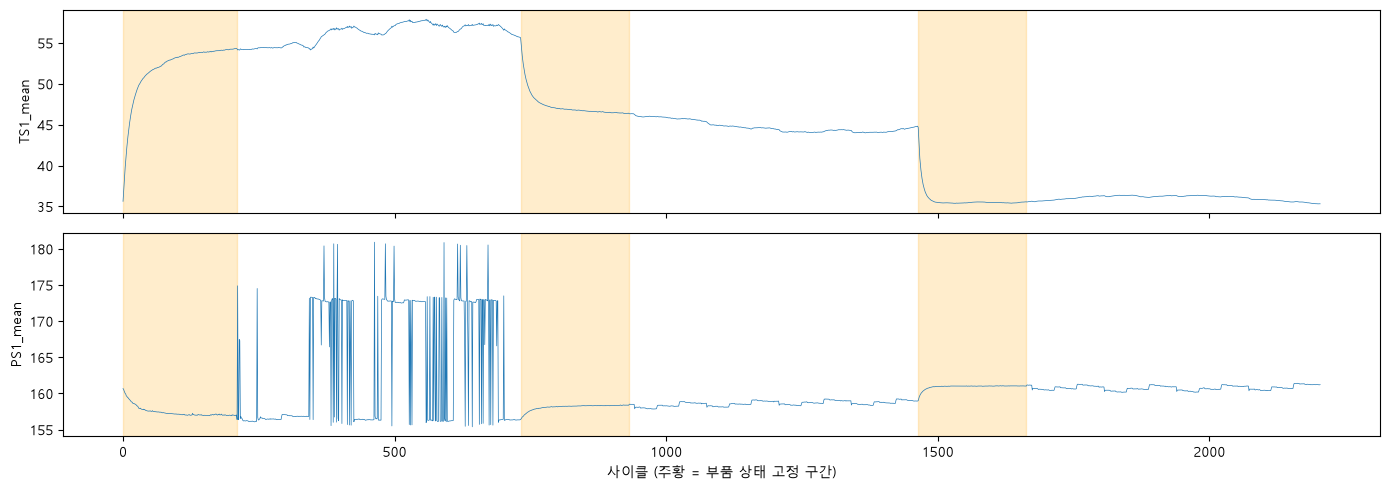

사이클 0~209 (210개), 상태 3-100-0-130, 안정 사이클 비율 0.00
사이클 732~931 (200개), 상태 20-100-0-90, 안정 사이클 비율 0.00
사이클 1464~1663 (200개), 상태 100-100-0-90, 안정 사이클 비율 0.00


In [3]:
key = cyc[list(COMP)].astype(str).agg("-".join, axis=1); run = (key != key.shift()).cumsum()
lens = run.value_counts(); RUNS = [cyc[run == r].sort_values("cycle") for r in lens[lens >= 200].index]
RUNS.sort(key=lambda s: s.cycle.min())
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for ax, f in zip(axes, ["TS1_mean", "PS1_mean"]):
    ax.plot(cyc["cycle"], cyc[f], lw=0.5)
    for s in RUNS: ax.axvspan(s.cycle.min(), s.cycle.max(), color="orange", alpha=0.2)
    ax.set_ylabel(f)
axes[-1].set_xlabel("사이클 (주황 = 부품 상태 고정 구간)"); plt.tight_layout(); plt.show()
for s in RUNS: print(f"사이클 {s.cycle.min()}~{s.cycle.max()} ({len(s)}개), 상태 {key[s.index[0]]}, 안정 사이클 비율 {(s.stable_flag == 0).mean():.2f}")

## 2. 기술통계: 고정 구간 안의 앞뒤 평균

In [4]:
FS = ["TS1_mean", "PS1_mean", "PS2_mean", "FS1_mean", "SE_mean"]
rows = []
for s in RUNS:
    m = len(s); a, b = s.iloc[: int(m * .3)], s.iloc[int(m * .7):]
    for f in FS: rows.append(dict(구간=f"{s.cycle.min()}~{s.cycle.max()}", 특징=f, 앞30=a[f].mean(), 뒤30=b[f].mean()))
display(pd.DataFrame(rows).pivot(index="특징", columns="구간", values=["앞30", "뒤30"]).round(2))

앞30                       뒤30                  
구간         0~209 1464~1663 732~931   0~209 1464~1663 732~931
특징                                                          
FS1_mean    6.65      6.68    6.63    6.60      6.69    6.64
PS1_mean  158.34    160.71  157.71  157.02    161.04  158.34
PS2_mean  107.54    109.30  106.79  106.33    109.60  107.37
SE_mean    69.33     68.00   68.87   69.74     67.99   68.94
TS1_mean   48.25     36.51   48.84   54.07     35.46   46.48

## 3. 가정 확인

KS 검정은 분포 모양을 가정하지 않는 비모수 검정입니다. 다만 표본이 독립이어야 하는데, H06에서 본 것처럼 자기상관이 강합니다. 그래서 효과 크기 D(0~1)를 함께 보고, D ≥ 0.5인 "크게 변한" 특징 수로 결론을 냅니다.

## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.

- 아래에서는 부품 상태 고정 구간 **안에서만** 정상성도 따로 봅니다.

,특징,계열,ADF_p,KPSS_p,판정
0,TS1_mean,원값,0.8718,0.010,비정상
1,TS1_mean,1차 차분,0.0000,0.023,추세·구조변화(둘 다 기각)
2,PS1_mean,원값,0.0002,0.100,정상
3,PS1_mean,1차 차분,0.0000,0.100,정상


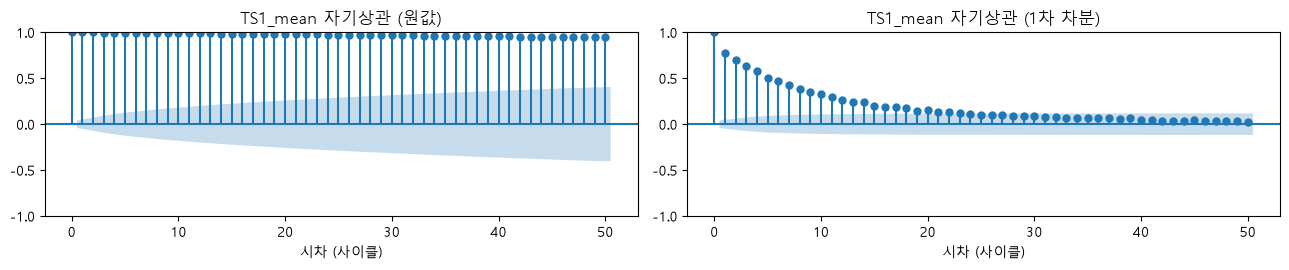

In [5]:
st = stationarity(cyc, ['TS1_mean', 'PS1_mean'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['TS1_mean'], "TS1_mean 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['TS1_mean'].diff(), "TS1_mean 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

In [6]:
for s in RUNS:
    print(f"[고정 구간 {s.cycle.min()}~{s.cycle.max()}]"); display(stationarity(s.reset_index(drop=True), ["TS1_mean", "PS1_mean"], diff=False))

[고정 구간 0~209]


,특징,계열,ADF_p,KPSS_p,판정
0,TS1_mean,원값,1.005232e-01,0.01,비정상
1,PS1_mean,원값,1.217685e-11,0.01,추세·구조변화(둘 다 기각)


[고정 구간 732~931]


,특징,계열,ADF_p,KPSS_p,판정
0,TS1_mean,원값,0.003355,0.01,추세·구조변화(둘 다 기각)
1,PS1_mean,원값,0.044314,0.01,추세·구조변화(둘 다 기각)


[고정 구간 1464~1663]


,특징,계열,ADF_p,KPSS_p,판정
0,TS1_mean,원값,1.556079e-08,0.016674,추세·구조변화(둘 다 기각)
1,PS1_mean,원값,3.435653e-08,0.010000,추세·구조변화(둘 다 기각)


## 5. 가설검정 (p-값) — 고정 구간별 KS

In [7]:
FEAT = features(cyc); summary = []; tops = {}
for s in RUNS:
    m = len(s); a, b = s.iloc[: int(m * .3)], s.iloc[int(m * .7):]
    rows = []
    for f in FEAT:
        x, y = a[f].dropna(), b[f].dropna()
        if len(x) < 5 or len(y) < 5 or (x.nunique() == 1 and y.nunique() == 1): continue
        D, p = stats.ks_2samp(x, y); rows.append(dict(특징=f, D=D, p=p))
    t = pd.DataFrame(rows); t["p_holm"] = holm(t["p"]); t = t.sort_values("D", ascending=False)
    nm = f"{s.cycle.min()}~{s.cycle.max()}"; tops[nm] = t
    summary.append(dict(구간=nm, 검정한_특징=len(t), 유의=int((t.p_holm < ALPHA).sum()), 크게변함_D05=int((t.D >= 0.5).sum()),
                        유의비율=(t.p_holm < ALPHA).mean(), 유온_앞=a.TS1_mean.mean(), 유온_뒤=b.TS1_mean.mean()))
summ = pd.DataFrame(summary); display(summ.style.format({"유의비율": "{:.0%}", "유온_앞": "{:.1f}", "유온_뒤": "{:.1f}"}))

,구간,검정한_특징,유의,크게변함_D05,유의비율,유온_앞,유온_뒤
0,0~209,62,60,51,97%,48.2,54.1
1,732~931,62,50,43,81%,48.8,46.5
2,1464~1663,66,44,22,67%,36.5,35.5


## 6. 효과 크기: 가장 많이 변한 특징

[0~209]


,특징,D,p,p_holm
0,PS1_mean,1.00,3.31e-37,2.05e-35
1,PS1_std,1.00,3.31e-37,2.05e-35
5,PS2_std,1.00,3.31e-37,2.05e-35
4,PS2_mean,1.00,3.31e-37,2.05e-35
13,PS5_max,1.00,3.31e-37,2.05e-35
12,PS5_min,1.00,3.31e-37,2.05e-35


[732~931]


,특징,D,p,p_holm
0,PS1_mean,1.00,2.07e-35,1.28e-33
1,PS1_std,1.00,2.07e-35,1.28e-33
2,PS1_min,1.00,2.07e-35,1.28e-33
4,PS2_mean,1.00,2.07e-35,1.28e-33
5,PS2_std,1.00,2.07e-35,1.28e-33
12,PS5_min,1.00,2.07e-35,1.28e-33


[1464~1663]


,특징,D,p,p_holm
32,FS2_min,1.00,2.07e-35,1.37e-33
30,FS2_mean,1.00,2.07e-35,1.37e-33
33,FS2_max,1.00,2.07e-35,1.37e-33
0,PS1_mean,0.97,1.48e-31,9.31e-30
1,PS1_std,0.90,7.56e-26,4.69e-24
4,PS2_mean,0.90,7.56e-26,4.69e-24


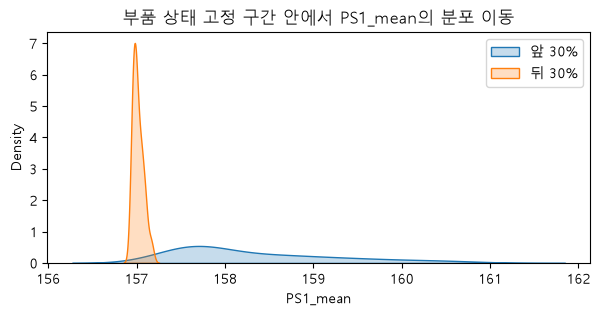

In [8]:
for nm, t in tops.items():
    print(f"[{nm}]"); display(t.head(6).style.format({"D": "{:.2f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))
s = RUNS[0]; m = len(s); f = tops[f"{s.cycle.min()}~{s.cycle.max()}"].iloc[0]["특징"]
fig, ax = plt.subplots(figsize=(7, 3))
sns.kdeplot(s.iloc[: int(m * .3)][f], ax=ax, fill=True, label="앞 30%"); sns.kdeplot(s.iloc[int(m * .7):][f], ax=ax, fill=True, label="뒤 30%")
ax.set_title(f"부품 상태 고정 구간 안에서 {f}의 분포 이동"); ax.legend(); plt.show()

## 7. 재확인: 시간과의 순위 상관

고정 구간 안에서 특징값이 사이클 번호와 함께 꾸준히 오르거나 내리는지(Spearman ρ) 봅니다.

In [9]:
rows = []
for s in RUNS:
    for f in ["TS1_mean", "PS1_mean", "PS2_mean", "SE_mean"]:
        r, p = stats.spearmanr(s["cycle"], s[f], nan_policy="omit"); rows.append(dict(구간=f"{s.cycle.min()}~{s.cycle.max()}", 특징=f, rho=r, p=p))
display(pd.DataFrame(rows).style.format({"rho": "{:.2f}", "p": "{:.2e}"}))

,구간,특징,rho,p
0,0~209,TS1_mean,1.00,0.00e+00
1,0~209,PS1_mean,-0.91,5.47e-82
2,0~209,PS2_mean,-0.91,3.86e-82
3,0~209,SE_mean,0.50,1.81e-14
4,732~931,TS1_mean,-1.00,1.28e-241
5,732~931,PS1_mean,0.98,1.11e-147
6,732~931,PS2_mean,0.99,4.48e-170
7,732~931,SE_mean,0.21,2.53e-03
8,1464~1663,TS1_mean,-0.25,4.00e-04
9,1464~1663,PS1_mean,0.81,1.51e-47


## 8. 최종 판정

In [10]:
final = pd.DataFrame([dict(가설="H07", 검정="KS (고정 구간 3개, Holm)", 통계량=f"유의한 특징 {summ.유의비율.min():.0%}~{summ.유의비율.max():.0%}",
    p="< .001 (상위 특징)", 효과크기=f"D ≥ 0.5 특징 {summ.크게변함_D05.min()}~{summ.크게변함_D05.max()}개",
    판정="H0 기각" if (summ.유의 > 0).all() else "H0 유지")])
display(final)
save_result("H07", title="부품 상태 고정 구간 안의 드리프트", test="KS (Holm)", stat=final.통계량[0],
            p=float(min(t.p_holm.min() for t in tops.values())), effect=final.효과크기[0], verdict=final.판정[0],
            note="고정 구간 3개 모두 불안정(안정 플래그 1) 구간")

,가설,검정,통계량,p,효과크기,판정
0,H07,"KS (고정 구간 3개, Holm)",유의한 특징 67%~97%,< .001 (상위 특징),D ≥ 0.5 특징 22~51개,H0 기각


저장: results/H07.json


## 9. 해석과 결정

- 부품 상태가 그대로인데도 특징 대부분(67~97%)이 앞뒤로 유의하게 변했고, 상당수는 분포가 완전히 갈렸습니다(D = 1). 부품과 무관한 **시간 변화(드리프트)**가 확실히 있습니다.
- **주의:** 세 고정 구간은 모두 냉각기를 바꾼 직후의 **불안정 구간**입니다(H09). 장치가 새 조건에 적응하는 동안의 변화가 섞여 있습니다. 발표에서는 "상태 변경 직후 수백 사이클 동안 센서 값이 계속 흘러간다"고 설명하는 것이 정확합니다.
- **결정:** 순서 블록 평가를 유지합니다. 운영에서는 **드리프트 감시 기능**(데이터가 학습 때와 달라지면 경보)을 검토합니다. 차별화 포인트 후보입니다.